# Support Vector Machine

In [1]:
# Load libraries

import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [4]:
cell_df = pd.read_csv("cell_samples.csv")
cell_df.sample(5)

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
125,1176406,1,1,1,1,2,1,2,1,1,2
108,1171710,1,1,1,1,2,1,2,3,1,2
539,1145420,6,1,1,1,2,1,2,1,1,2
190,1210963,10,10,10,8,6,8,7,10,1,4
538,1135090,4,1,1,1,2,1,2,1,1,2


In [ ]:
# change the value into the column class to 0 and 1, where 0 is benign(2) and 1 is malignant(4)
cell_df['Class'] = cell_df['Class'].map({2: 0, 4: 1})
cell_df.sample(5)

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
85,1147748,5,10,6,1,10,4,4,10,10,1
235,1241232,3,1,4,1,2,?,3,1,1,0
133,1180523,3,1,1,1,2,1,2,2,1,0
411,1238464,1,1,1,1,1,?,2,1,1,0
283,492268,10,4,6,1,2,10,5,3,1,1


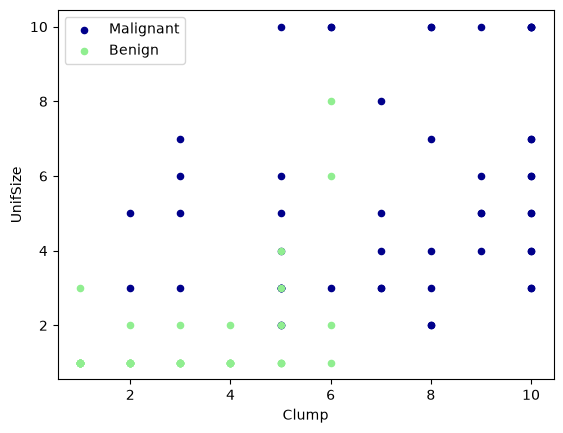

In [6]:
ax = cell_df[cell_df['Class'] == 1][0:50].plot(kind='scatter', x='Clump', y='UnifSize', color='DarkBlue', label='Malignant')
ax = cell_df[cell_df['Class'] == 0][0:50].plot(kind='scatter', x='Clump', y='UnifSize', color='LightGreen', label='Benign', ax=ax)
plt.show()

## Data Preprocessing and data types

In [7]:
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc          str
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [8]:
# Drop non-numerical values and convert the column BareNuc to numeric values
cell_df = cell_df[pd.to_numeric(cell_df['BareNuc'], errors='coerce').notnull()]
cell_df['BareNuc'] = cell_df['BareNuc'].astype('int')
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [9]:
cell_df.sample(5)

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
317,709287,6,8,7,8,6,8,8,9,1,1
536,1113061,5,1,1,1,2,1,3,1,1,0
234,1236043,3,3,2,1,3,1,3,6,1,0
14,1044572,8,7,5,10,7,9,5,5,4,1
367,160296,5,8,8,10,5,10,8,10,3,1


In [10]:
# Remove the id column and separate the features and labels into a new data frame
features_df = cell_df[['Clump', 'UnifSize', 'UnifShape', 'MargAdh', 'SingEpiSize', 'BareNuc', 'BlandChrom', 'NormNucl', 'Mit']]
X = np.asarray(features_df)
X[0:5]


array([[ 5,  1,  1,  1,  2,  1,  3,  1,  1],
       [ 5,  4,  4,  5,  7, 10,  3,  2,  1],
       [ 3,  1,  1,  1,  2,  2,  3,  1,  1],
       [ 6,  8,  8,  1,  3,  4,  3,  7,  1],
       [ 4,  1,  1,  3,  2,  1,  3,  1,  1]])

In [11]:
# Separate the labels from the features into a new data frame, and convert the labels into int typ number and after to a numpy array
cell_df['Class'] = cell_df['Class'].astype('int')
y = np.asarray(cell_df['Class'])
y[0:5]

array([0, 0, 0, 0, 0])

In [12]:
# Build groups for training and testing data, where 20% of the data is used for testing and 80% for training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
print('Train set:', X_train.shape, y_train.shape)
print('Test set:', X_test.shape, y_test.shape)

Train set: (546, 9) (546,)
Test set: (137, 9) (137,)


# Modeling with SVM
Kernel options:
1. Linear
2. Polynominal
3. Radial Basis (RBF)
4. Sigmoid


In [13]:
# importa svm from sklearn and create a classifier
from sklearn import svm
clf = svm.SVC(kernel='rbf')
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [14]:
# Predict the labels for the test set
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 1, 0])

# Evaluation

In [ ]:
# Build the confusion matrix 
from sklearn.metrics import confusion_matrix
yhat = clf.predict(X_test)
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

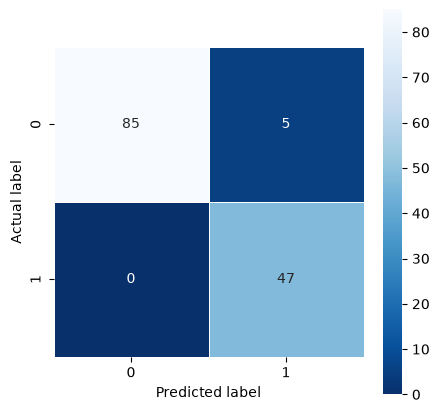

In [ ]:
# Heat map of the confusion matrix
import seaborn as sns
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt=".0f", linewidths=.5, linecolor='white', square=True, cmap='Blues_r');
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

# Acuracy statisticals


In [18]:
# Accuracy score of the model
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[1,0])
print(classification_report(y_test, yhat, target_names=['Benign(0)', 'Malignant(1)']))

              precision    recall  f1-score   support

   Benign(0)       1.00      0.94      0.97        90
Malignant(1)       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Estimate the precision levels

The precision is defined as the ercentage of relative to the total of the correct predictions 
- The total is estimated by column
- It answers the question: What percentage of the times is the predicted true? 

In [ ]:
# Accuracy score of the model for benign cells
accuracyBenign = cm[0,0] / (cm[0,0] + cm[1,0])
accuracyBenign

np.float64(1.0)

In [23]:
# Accuracy score of the model for malignant cells
accuracyMalignant = cm[1,1] / (cm[0,1] + cm[1,1])
accuracyMalignant

np.float64(0.9038461538461539)

# Estimate the recall levels

The recall is defined as the fraction of actual positive instances that model correctly identifies.
- The total is estimated by row
- It answers the question: how many did the model mange to find? 

In [25]:
# Recall score of the model for benign cells
recallBenign = cm[0,0] / (cm[0,0] + cm[0,1])
recallBenign


np.float64(0.9444444444444444)

In [26]:
# Recall score of the model for malignant cells
recallMalignant = cm[1,1] / (cm[1,0] + cm[1,1])
recallMalignant

np.float64(1.0)

# Estimate the score F1

The score F1 is defined as a harmonic mean of the precision and recall, where F1 score reaches its best value at 1 and the worst score at 0. 
- F1_score = 2 * (Precision * Recall) / (Precision + Recall)

In [27]:
# Estimate f1-score for benign cells
f1ScoreBenign = 2 * (accuracyBenign * recallBenign) / (accuracyBenign + recallBenign)
f1ScoreBenign

np.float64(0.9714285714285714)

In [28]:
# Estumate f1-score for malignant cells
f1ScoreMalignant = 2 * (accuracyMalignant * recallMalignant) / (accuracyMalignant + recallMalignant)
f1ScoreMalignant    

np.float64(0.9494949494949495)

# Estimate the support

Support  is defined as the total number of actual occurrences (ground the thruth) of a specific class in the dataset

In [29]:
# Estimate the support of the model for benign cells
supportBenign = cm[0,0] + cm[0,1]
supportBenign

np.int64(90)

In [30]:
# Estimate the support of the model for malignant cells
supportMalignant = cm[1,0] + cm[1,1]
supportMalignant

np.int64(47)

# Estimate the global accuracy

Global accuracy mesures the fraction of all predictions that the model got correct, regardless of the class.

In [3]:
# Estimate the global accuracy of the model, defined by actual, incorrectly predicted labels divided by the total number of labels
actual = cm[0,0] + cm[1,1]
incorrect = cm[0,1] + cm[1,0]

globalAccuracy = actual / (actual + incorrect)
globalAccuracy

NameError: name 'cm' is not defined

# Simple means by indicator (Macrto averange)

Simple mean by precision, recall and score f1

In [32]:
# Mean average of the model, defined by the sum of the precisions for both classes divided by the number of classes
meanAveragePrecision = (accuracyBenign + accuracyMalignant) / 2
meanAveragePrecision

np.float64(0.9519230769230769)

In [33]:
# Mean averange of the model, defined by the sum of the recalls for both classes divided by the number of classes
meanAverageRecall = (recallBenign + recallMalignant) / 2
meanAverageRecall

np.float64(0.9722222222222222)

In [35]:
# Mean average of the model, defined by the sum of the f1 scores for both classes divided by the number of classes
meanAverageF1 = (f1ScoreBenign + f1ScoreMalignant) / 2
meanAverageF1

np.float64(0.9604617604617605)

# Weighted average
Weighted Average calculate metrics for each label, and find their average weighted by support (the number of instances of each class)


In [36]:
# Calculate the weight for bening and malignant cells, defined by the support for benign and malignant cells divided by the total number of labels, respectively
weightBenign = supportBenign / (supportBenign + supportMalignant)
weightMalignant = supportMalignant / (supportBenign + supportMalignant)

In [37]:
# Calculate the mean average for precision, recall, f1-score and global accuracy of the model, defined by the sum of the global accuracy, mean average precision, mean average recall and mean average f1 divided by 4
weightAvgPrecision = weightBenign * accuracyBenign + weightMalignant * accuracyMalignant
weightAvgPrecision

np.float64(0.967012914093206)

In [42]:
# Calculate the weighted averages for recall 
weightAvgRecall = weightBenign * recallBenign + weightMalignant * recallMalignant
weightAvgRecall


np.float64(0.9635036496350364)

In [41]:
# Calculate the weighted averages for f1-score
weightAvgF1 = weightBenign * f1ScoreBenign + weightMalignant * f1ScoreMalignant
weightAvgF1

np.float64(0.9639038982104675)

# SVN test  with a lineal kernel

In [45]:
# test the model with a linear kernel
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# Confusion matrix for the linear kernel
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [46]:
# Clasification report for the linear kernel
print(classification_report(y_test, yhat, target_names=['Benign(0)', 'Malignant(1)']))

              precision    recall  f1-score   support

   Benign(0)       1.00      0.94      0.97        90
Malignant(1)       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# SVN test  with a poly kernel

In [47]:
# test the model with a polynomial kernel
clf = svm.SVC(kernel='poly')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# Confusion matrix for the linear kernel
cm = confusion_matrix(y_test, yhat)
cm

array([[86,  4],
       [ 0, 47]])

In [48]:
print(classification_report(y_test, yhat, target_names=['Benign(0)', 'Malignant(1)']))

              precision    recall  f1-score   support

   Benign(0)       1.00      0.96      0.98        90
Malignant(1)       0.92      1.00      0.96        47

    accuracy                           0.97       137
   macro avg       0.96      0.98      0.97       137
weighted avg       0.97      0.97      0.97       137



# SVN test  with a poly kernel

In [49]:
# test the model with a sigmoid kernel
clf = svm.SVC(kernel='sigmoid')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# Confusion matrix for the linear kernel
cm = confusion_matrix(y_test, yhat)
cm

array([[54, 36],
       [47,  0]])

In [ ]:
print(classification_report(y_test, yhat, target_names=['Benign(0)', 'Malignant(1)']))

              precision    recall  f1-score   support

   Benign(0)       0.53      0.60      0.57        90
Malignant(1)       0.00      0.00      0.00        47

    accuracy                           0.39       137
   macro avg       0.27      0.30      0.28       137
weighted avg       0.35      0.39      0.37       137

